# Member 2 : Traffic Pattern Analyst (MySQL + Python)

Steps:
1. Location-wise Traffic
2. Hourly Traffic Pattern
3. Speed vs Hour
4. Weekday vs Weekend
5. Road Type Intelligence
6. Traffic Heat Map

**Note:** Neeche `load_data_sql()` function mein apna MySQL username, password aur database naam daal do (jahan `traffic` table hai).

## Step 0: Setup - Libraries (agar install nahi hain toh yeh cells chalao)

In [1]:
!pip install mysql-connector-python

In [2]:
!pip install sqlalchemy pymysql

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine   # to create sql to python connect....
import os

sns.set_style("whitegrid")
%matplotlib inline

## Step 0.1: MySQL connection function

The notebook reads connection settings from environment variables: `TRAFFIC_DB_USER`, `TRAFFIC_DB_PASSWORD`, `TRAFFIC_DB_HOST`, and `TRAFFIC_DB_NAME`. Defaults are `root`, an empty password, `localhost`, and `traffic_intelligence`. Make sure your MySQL database contains a table named `traffic` before running the analysis.

In [4]:
def get_query_result(query):
    db_user = os.getenv('TRAFFIC_DB_USER', 'root')
db_password = os.getenv('TRAFFIC_DB_PASSWORD', '')
db_host = os.getenv('TRAFFIC_DB_HOST', 'localhost')
db_name = os.getenv('TRAFFIC_DB_NAME', 'traffic_intelligence')
db_creds = f'mysql+mysqlconnector://{db_user}:{db_password}@{db_host}/{db_name}'
    engine = create_engine(db_creds)
    return pd.read_sql(query, engine)

# Test connection - top 5 rows dikhengi agar connection sahi hai
get_query_result("SELECT * FROM traffic LIMIT 5;")

,record_id,timestamp,location_name,latitude,longitude,road_type,lane_count,day_of_week,hour,is_weekend,...,signal_status,public_transport_delay_min,pollution_index_aqi,event_nearby,construction_work,accident_reported,accident_severity,prev_hour_congestion,congestion_level,target_congestion_next_hour
0,1,2024-01-01 00:04:00,Wakad Bridge,18.598795,73.763022,Highway,6,0,0,0,...,Working,3.6,55,0,1,0,None,Low,Low,Low
1,2,2024-01-01 00:09:00,Magarpatta Rd,18.515726,73.927038,Local,2,0,0,0,...,Working,0.4,59,0,0,0,None,Low,Low,Low
2,3,2024-01-01 00:11:00,Kharadi IT Park Rd,18.544116,73.934890,Highway,6,0,0,0,...,Working,1.6,67,0,0,0,None,Low,Low,Low
3,4,2024-01-01 00:15:00,Kothrud Depot,18.507846,73.801938,Local,2,0,0,0,...,Working,0.0,72,0,0,0,None,Low,Low,Low
4,5,2024-01-01 00:16:00,Swargate Signal,18.499092,73.859743,Local,2,0,0,0,...,Working,6.3,60,1,0,0,None,Low,Low,Low


## Step 1: Location-wise Traffic

In [5]:
query1 = """
    SELECT location_name,
           AVG(vehicle_count)     AS avg_vehicles,
           AVG(occupancy_percent) AS avg_occupancy,
           AVG(avg_speed_kmph)    AS avg_speed
    FROM traffic
    GROUP BY location_name
    ORDER BY avg_occupancy DESC;
"""
loc_df = get_query_result(query1)
loc_df.round(1)

,location_name,avg_vehicles,avg_occupancy,avg_speed
0,Katraj Bypass,1157.6,65.9,30.4
1,Kharadi IT Park Rd,1141.6,65.4,30.5
2,Wakad Bridge,1140.3,65.2,30.6
3,Warje Flyover,1139.7,65.2,30.7
4,Hinjewadi Phase 1 Rd,1130.3,64.9,30.7
5,Shivajinagar Junction,590.5,55.5,22.6
6,Viman Nagar,589.9,55.4,22.7
7,Hadapsar Industrial Rd,587.5,55.3,22.8
8,Chinchwad Station Rd,586.2,55.3,22.7
9,Aundh Main Rd,587.9,55.1,22.8


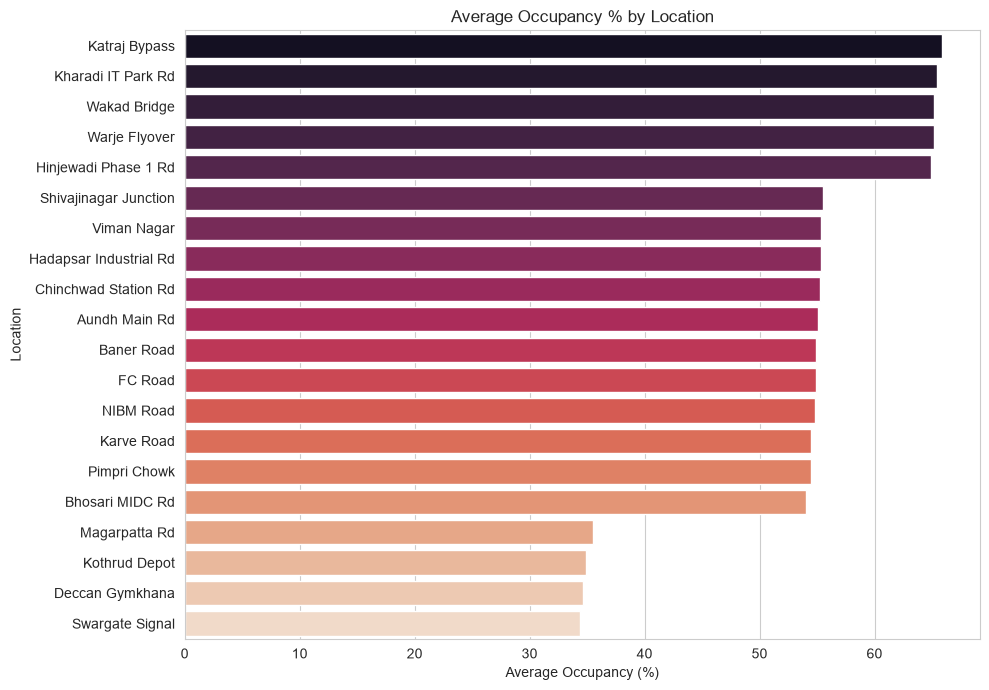

In [6]:
plt.figure(figsize=(10,7))
sns.barplot(data=loc_df, x="avg_occupancy", y="location_name", hue="location_name", palette="rocket", legend=False)
plt.title("Average Occupancy % by Location")
plt.xlabel("Average Occupancy (%)")
plt.ylabel("Location")
plt.tight_layout()
plt.show()

## Step 2 & 3: Hourly Traffic Pattern + Speed vs Hour

In [7]:
query2 = """
    SELECT hour,
           AVG(vehicle_count)     AS avg_vehicles,
           AVG(occupancy_percent) AS avg_occupancy,
           AVG(avg_speed_kmph)    AS avg_speed
    FROM traffic
    GROUP BY hour
    ORDER BY hour;
"""
hr_df = get_query_result(query2)
hr_df.round(1)

,hour,avg_vehicles,avg_occupancy,avg_speed
0,0,286.9,26.4,33.1
1,1,289.1,26.5,33.1
2,2,291.4,26.5,33.5
3,3,293.9,26.6,33.8
4,4,294.7,27.0,33.1
5,5,324.7,30.0,31.8
6,6,436.9,40.1,28.3
7,7,685.9,62.8,20.6
8,8,1009.3,83.9,14.0
9,9,1162.4,89.2,12.4


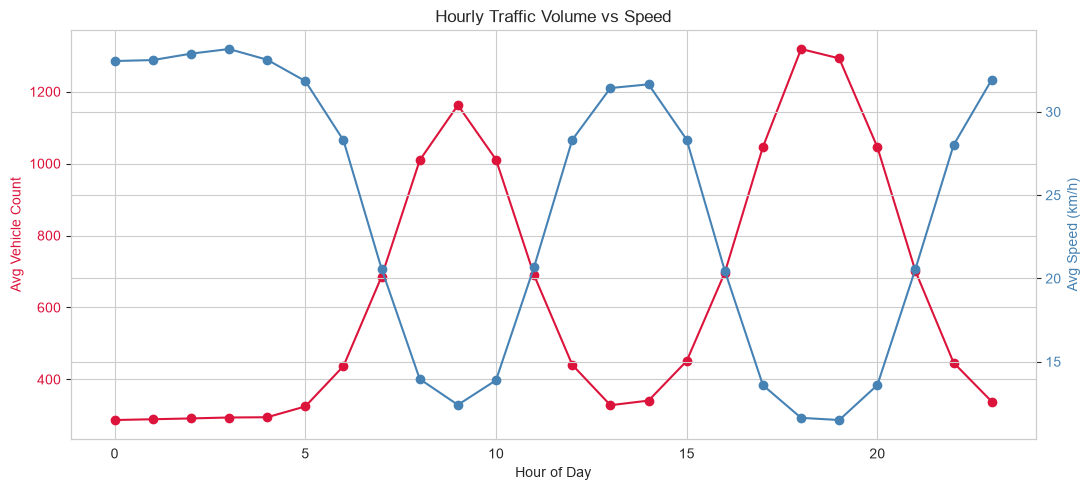

In [8]:
fig, ax1 = plt.subplots(figsize=(11,5))
ax1.plot(hr_df["hour"], hr_df["avg_vehicles"], color="crimson", marker="o", label="Vehicle Count")
ax1.set_xlabel("Hour of Day")
ax1.set_ylabel("Avg Vehicle Count", color="crimson")
ax1.tick_params(axis="y", labelcolor="crimson")

ax2 = ax1.twinx()
ax2.plot(hr_df["hour"], hr_df["avg_speed"], color="steelblue", marker="o", label="Avg Speed (km/h)")
ax2.set_ylabel("Avg Speed (km/h)", color="steelblue")
ax2.tick_params(axis="y", labelcolor="steelblue")

plt.title("Hourly Traffic Volume vs Speed")
fig.tight_layout()
plt.show()

## Step 4: Weekday vs Weekend

In [9]:
query4 = """
    SELECT is_weekend,
           AVG(vehicle_count)     AS avg_vehicles,
           AVG(occupancy_percent) AS avg_occupancy,
           AVG(avg_speed_kmph)    AS avg_speed
    FROM traffic
    GROUP BY is_weekend;
"""
wk_df = get_query_result(query4)
wk_df["day_type"] = wk_df["is_weekend"].map({0: "Weekday", 1: "Weekend"})
wk_df.round(1)

,is_weekend,avg_vehicles,avg_occupancy,avg_speed,day_type
0,0,664.4,54.7,23.7,Weekday
1,1,564.3,50.5,25.0,Weekend


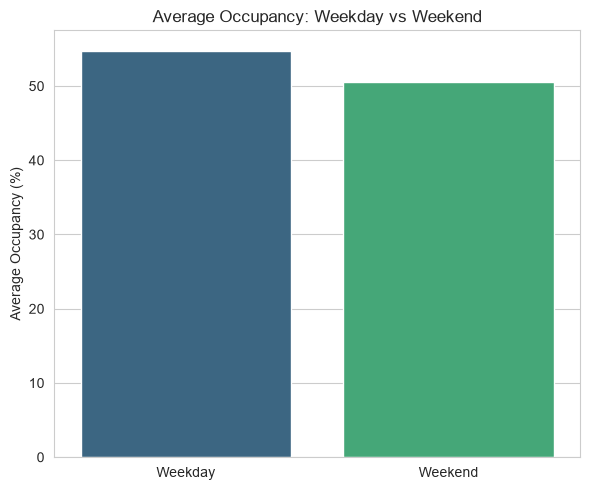

In [10]:
plt.figure(figsize=(6,5))
sns.barplot(data=wk_df, x="day_type", y="avg_occupancy", hue="day_type", palette="viridis", legend=False)
plt.title("Average Occupancy: Weekday vs Weekend")
plt.xlabel("")
plt.ylabel("Average Occupancy (%)")
plt.tight_layout()
plt.show()

## Step 5: Road Type Intelligence

In [11]:
query5 = """
    SELECT road_type,
           AVG(vehicle_count)     AS avg_vehicles,
           AVG(occupancy_percent) AS avg_occupancy,
           AVG(avg_speed_kmph)    AS avg_speed
    FROM traffic
    GROUP BY road_type
    ORDER BY avg_occupancy DESC;
"""
rt_df = get_query_result(query5)
rt_df.round(1)

,road_type,avg_vehicles,avg_occupancy,avg_speed
0,Highway,1141.9,65.3,30.6
1,Arterial,571.2,54.9,22.8
2,Local,174.6,34.9,19.4


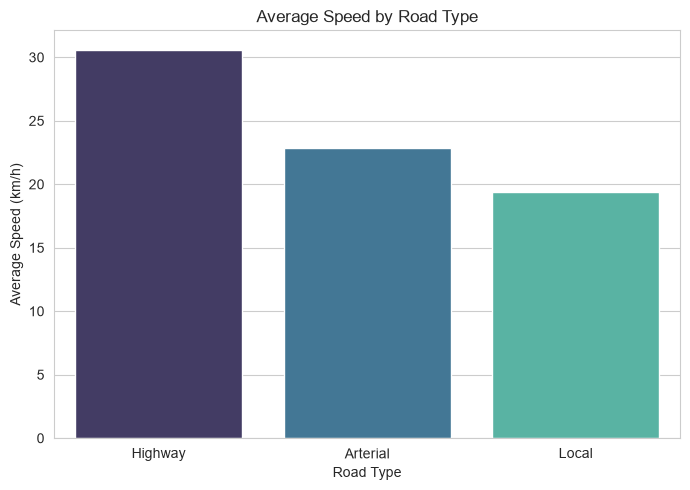

In [12]:
plt.figure(figsize=(7,5))
sns.barplot(data=rt_df, x="road_type", y="avg_speed", hue="road_type", palette="mako", legend=False)
plt.title("Average Speed by Road Type")
plt.xlabel("Road Type")
plt.ylabel("Average Speed (km/h)")
plt.tight_layout()
plt.show()

## Step 6: Traffic Heat Map (Location vs Hour)

In [13]:
query6 = """
    SELECT location_name, hour,
           AVG(occupancy_percent) AS avg_occupancy
    FROM traffic
    GROUP BY location_name, hour;
"""
heat_df = get_query_result(query6)

# Long format -> wide format (matrix) for the heatmap
pivot = heat_df.pivot(index="location_name", columns="hour", values="avg_occupancy")
pivot.head()

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
location_name,,,,,,,,,,,,,,,,,,,,,
Aundh Main Rd,26.835714,26.648824,26.560996,26.573934,27.521667,30.214218,41.088325,62.117961,87.434978,93.283193,...,31.216667,41.035323,64.039791,89.035821,96.200467,97.753953,89.905357,64.344041,41.631651,30.516749
Baner Road,26.144762,26.483568,26.485514,26.350400,26.833333,30.606667,39.547594,62.561194,88.569118,95.604265,...,31.630952,40.882018,64.189520,89.967980,96.217890,96.118605,88.431776,64.073684,42.961111,30.731280
Bhosari MIDC Rd,26.432759,26.210244,26.821579,26.322222,27.340704,29.644292,40.106635,62.812444,86.981283,93.744954,...,30.466667,41.257426,62.874731,88.383744,95.902116,96.255760,88.759135,63.383000,41.839076,31.213974
Chinchwad Station Rd,26.943318,26.929592,26.494258,26.593596,26.961468,30.630000,40.081340,63.037056,87.304878,94.340933,...,31.344628,41.053883,65.673913,89.650704,97.532301,96.596859,88.457851,65.864130,41.252558,30.858911
Deccan Gymkhana,16.077209,15.897340,15.799550,15.620918,16.110185,17.825532,23.916432,39.275510,56.242857,63.177512,...,18.859709,24.461058,38.341262,56.456345,70.288106,72.841148,58.076168,37.931858,24.616034,18.764103


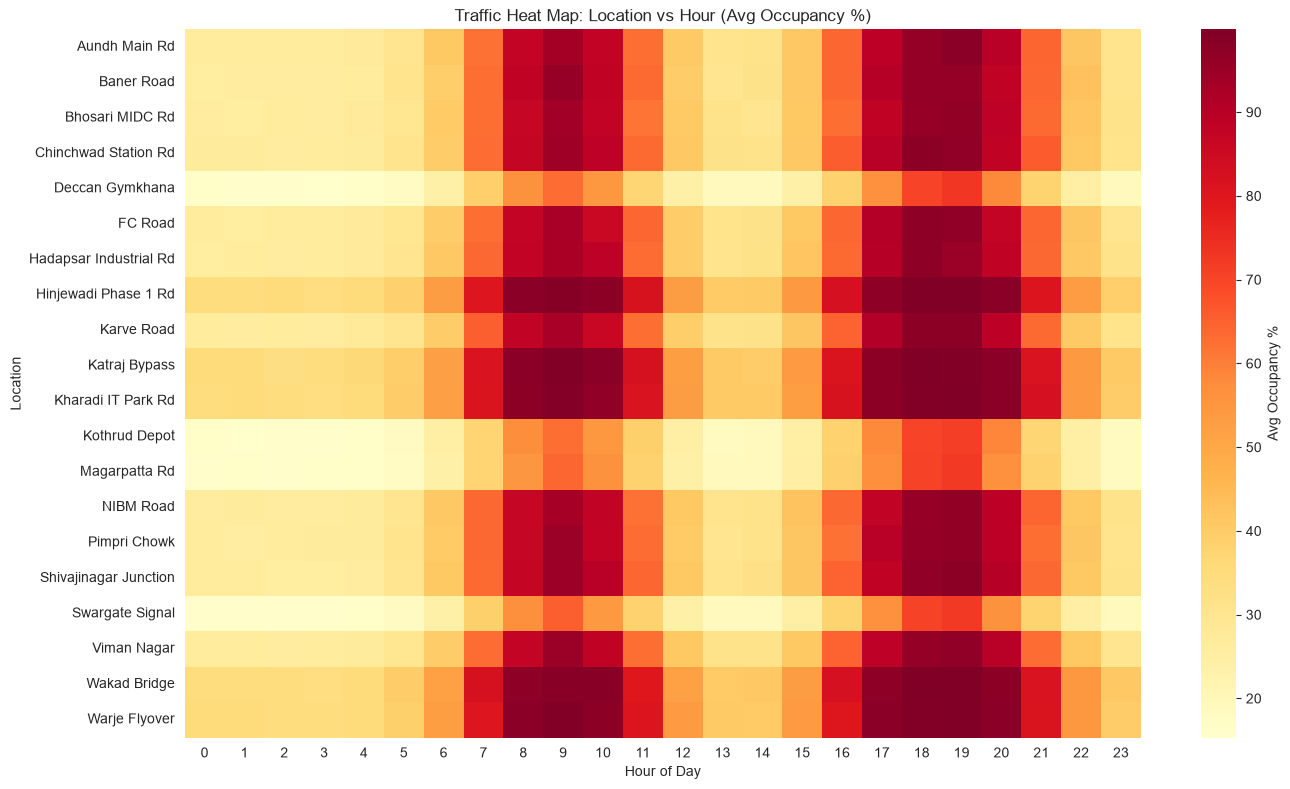

In [14]:
plt.figure(figsize=(14,8))
sns.heatmap(pivot, cmap="YlOrRd", cbar_kws={"label": "Avg Occupancy %"})
plt.title("Traffic Heat Map: Location vs Hour (Avg Occupancy %)")
plt.xlabel("Hour of Day")
plt.ylabel("Location")
plt.tight_layout()
plt.show()

## Summary
- **Peak hours:** 8-9 AM aur 6-7 PM (occupancy sabse zyada, speed sabse kam)
- **Sabse busy locations:** Highway wale roads (Katraj Bypass, Kharadi IT Park, Wakad Bridge, Warje Flyover, Hinjewadi)
- **Weekday** par traffic weekend se zyada hota hai
- **Road type:** Highway > Arterial > Local (traffic volume ke hisaab se)